# Medical Insurance Cost Prediction
### 1.Introduction
### 2.Data
### 3.Data Wrangling
### 4.Preliminary Analysis
### 5.Main Analysis
### 6.Conclusions

## Data section

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/Users/nhonn0249/PythonUSF/final projecr/insurance_project.ipynb/insurance.csv')

print(df.head())
print(df.shape)
print(df.info())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
(1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None


#### Dataset contains 1,338 records and 7 columns.

#### Explain the variables in the dataset.

#### Identify charges as the target variable.

In [6]:
#Missing values:
print(df.isnull().sum())

#Duplicate rows
print("Duplicates:", df.duplicated().sum())

#Remove duplicates

df = df.drop_duplicates()
print(df.shape)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicates: 1
(1337, 7)


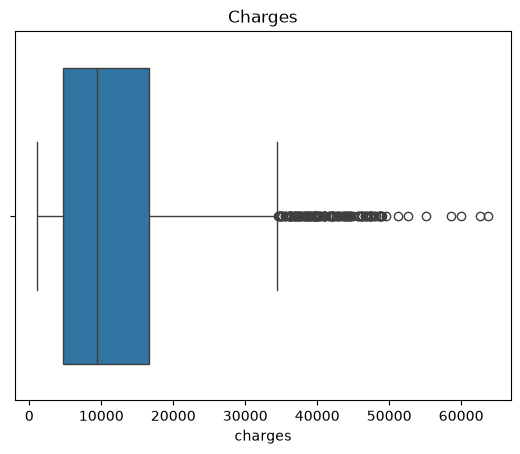

In [7]:
#Outliers: boxplots show unusual values as dots
sns.boxplot(x=df["charges"])
plt.title("Charges")
plt.show()

In [8]:
#Summary statistics
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


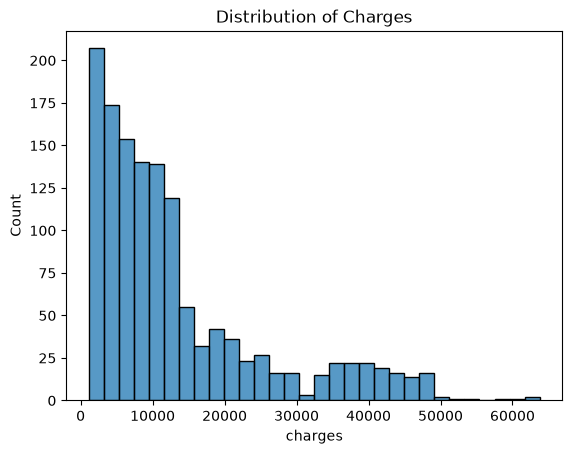

In [9]:
#Distribution of charges
sns.histplot(df["charges"], bins=30)
plt.title("Distribution of Charges")
plt.show()

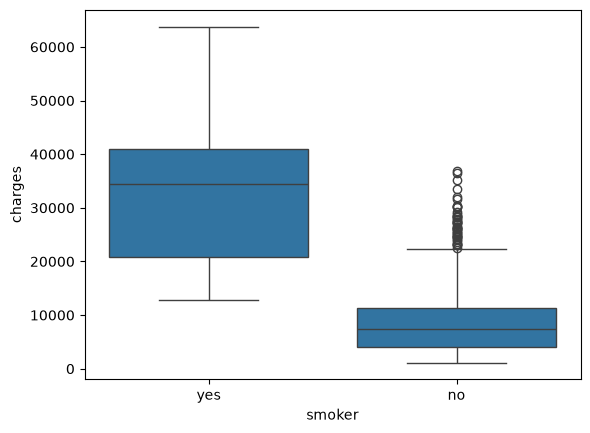

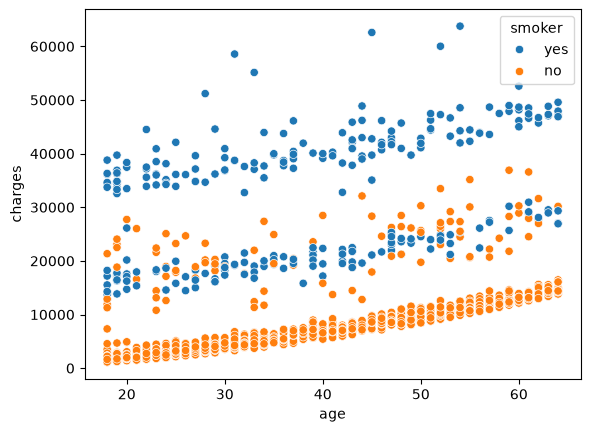

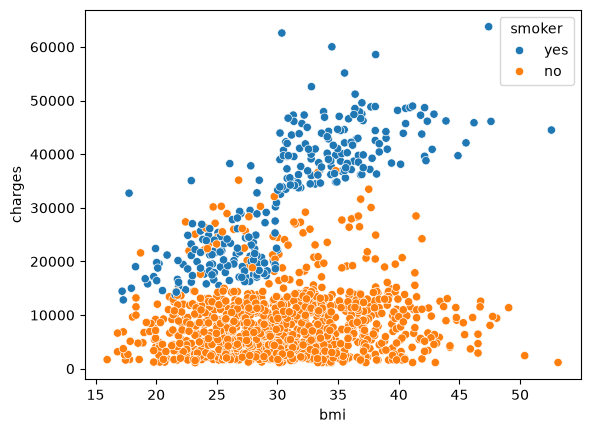

In [10]:
#Smoker vs non-smoker: the key finding
sns.boxplot(x="smoker", y="charges", data=df)
plt.show()

#Scatter plot: age vs charges, colored by smoker
sns.scatterplot(x="age", y="charges", hue="smoker", data=df)
plt.show()

#BMi vs chatges, colored by smoker
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df)
plt.show()

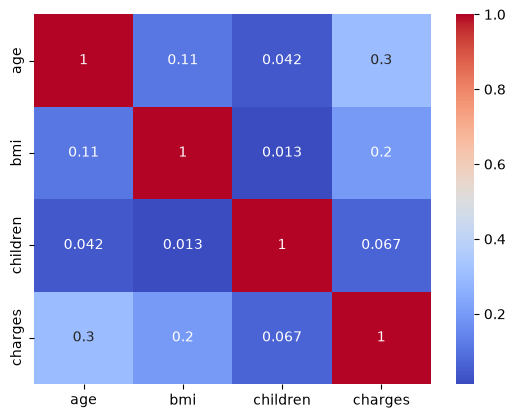

In [11]:
#correlations
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score


# Convert text columns to numbers
df_model = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True)

#X = clues, y = the answer we want to predict
X = df_model.drop("charges", axis=1)
y = df_model["charges"]

# Train on 80%, test on the hidden 20%

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train both models and compare them

for name, model in [("Linear Regression", LinearRegression()),
                    ("Random Forest", RandomForestRegressor(random_state=42))]:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(name)
    print("  Average error ($):", round(mean_absolute_error(y_test, preds)))
    print("  R2 score:", round(r2_score(y_test, preds), 3))



Linear Regression
  Average error ($): 4177
  R2 score: 0.807
Random Forest
  Average error ($): 2633
  R2 score: 0.88
